## Bar charts

In [2]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("../data/checking-logs.sqlite")


In [3]:
query = """
    SELECT
        timestamp
    FROM
        checker
    WHERE
        uid LIKE 'user_%'
"""
df = pd.read_sql(query, conn, parse_dates=['timestamp'])

df['hour'] = df['timestamp'].dt.hour
df['date'] = df['timestamp'].dt.date
df['daytype'] = df['timestamp'].dt.dayofweek.apply(lambda x: 'working_day' if x < 5 else 'weekend')

commit_per_day_hour = df.groupby(['date', 'hour', 'daytype']).size().reset_index(name='commits_count')
avg_commit = commit_per_day_hour.groupby(['daytype', 'hour'])['commits_count'].mean().reset_index()
avg_commit.tail()

,daytype,hour,commits_count
37,working_day,19,17.833333
38,working_day,20,14.076923
39,working_day,21,24.333333
40,working_day,22,3.750000
41,working_day,23,5.000000


## pivot table and plot

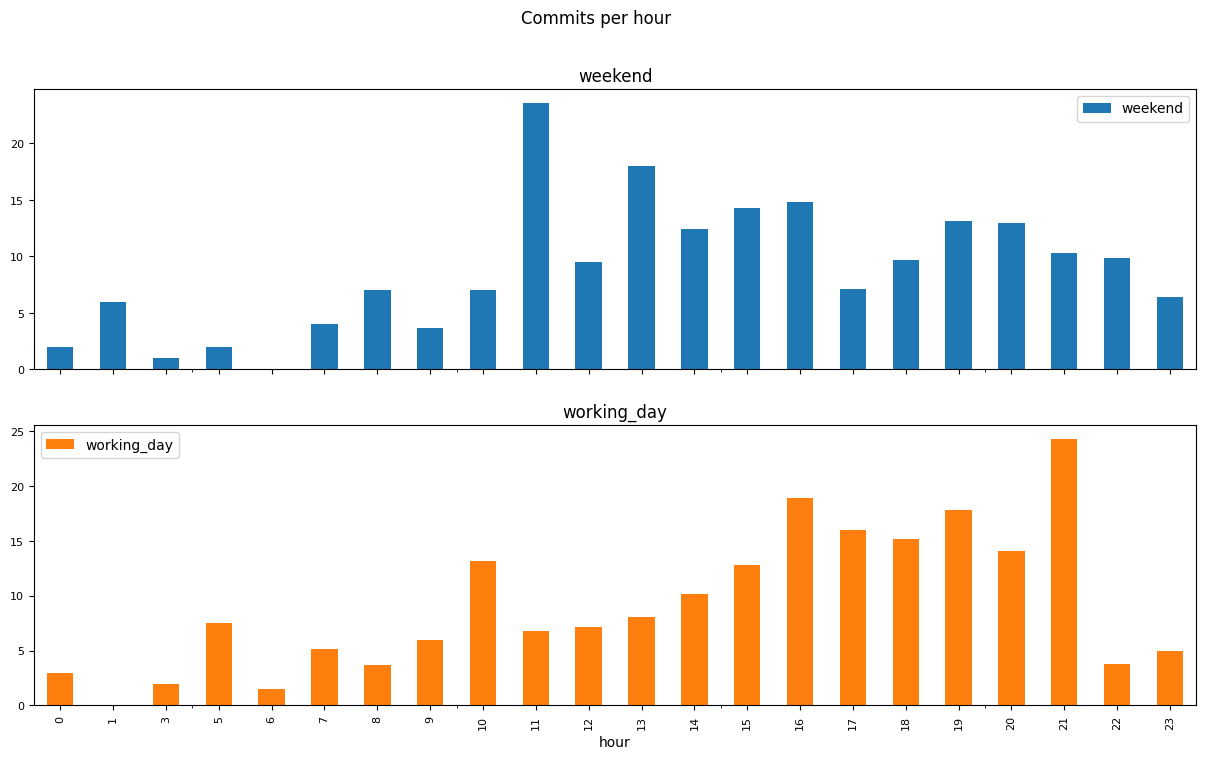

In [4]:
processed_df = avg_commit.pivot_table(
    index='hour',
    columns='daytype',
    values='commits_count'
)
reordered = processed_df[['weekend', 'working_day']]
ax = reordered.plot(
    kind='bar',
    subplots=True,
    figsize=(15,8),
    fontsize=8,
    rot=90,
    title='Commits per hour'
)
conn.close()

In [5]:
reordered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 22 entries, 0 to 23
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   weekend      21 non-null     float64
 1   working_day  21 non-null     float64
dtypes: float64(2)
memory usage: 440.0 bytes


### Is the dynamic different on working days and weekends?

The largest hour on working days: 21, and on weekends: 11